In [1]:
import pandas as pd
import numpy as np

In [2]:
mall = pd.read_csv('Mall_Customers.csv')

In [3]:
mall

,CustomerID,Genre,Age,Annual Income (k$),Spending Score (1-100)
0,1,Male,19,15,39
1,2,Male,21,15,81
2,3,Female,20,16,6
3,4,Female,23,16,77
4,5,Female,31,17,40
...,...,...,...,...,...
195,196,Female,35,120,79
196,197,Female,45,126,28
197,198,Male,32,126,74
198,199,Male,32,137,18


In [4]:
mall.isna().sum()

CustomerID                0
Genre                     0
Age                       0
Annual Income (k$)        0
Spending Score (1-100)    0
dtype: int64

In [5]:
import matplotlib.pyplot as plt

(array([ 88.,   0.,   0.,   0.,   0.,   0.,   0.,   0.,   0., 112.]),
 array([0. , 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1. ]),
 <BarContainer object of 10 artists>)

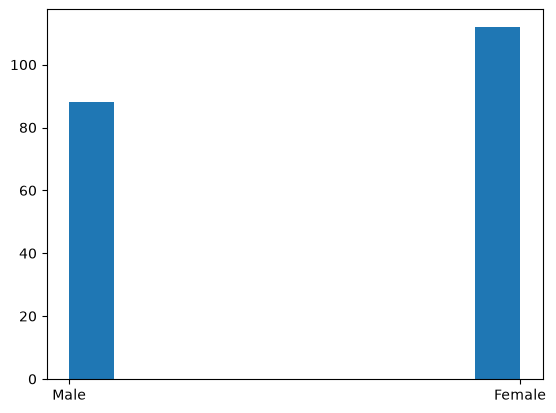

In [6]:
plt.hist(mall['Genre'])

In [7]:
X = mall[['Annual Income (k$)','Spending Score (1-100)']]

In [8]:
from sklearn.cluster import KMeans

kmeans = KMeans(n_clusters=3,random_state=42,n_init=10).fit(X)

In [9]:
pred = kmeans.predict(X)
pred

array([2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1, 0, 1,
       0, 1], dtype=int32)

In [10]:
kmeans.cluster_centers_

array([[87.        , 18.63157895],
       [86.53846154, 82.12820513],
       [44.15447154, 49.82926829]])

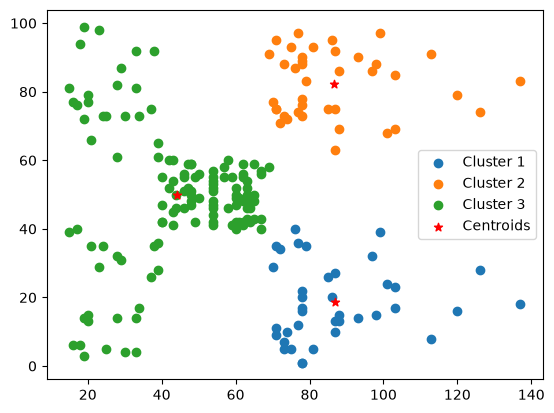

In [11]:
plt.scatter(X.loc[kmeans.labels_ == 0, "Annual Income (k$)"],X.loc[kmeans.labels_ == 0, "Spending Score (1-100)"],label=f"Cluster 1")
plt.scatter(X.loc[kmeans.labels_ == 1, "Annual Income (k$)"],X.loc[kmeans.labels_ == 1, "Spending Score (1-100)"],label=f"Cluster 2")
plt.scatter(X.loc[kmeans.labels_ == 2, "Annual Income (k$)"],X.loc[kmeans.labels_ == 2, "Spending Score (1-100)"],label=f"Cluster 3")

plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],marker="*", color="red", label="Centroids")

plt.legend()
plt.show()


In [12]:
wcss = []
for k in range(1,11):
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X)
    wcss.append(kmeans.inertia_)

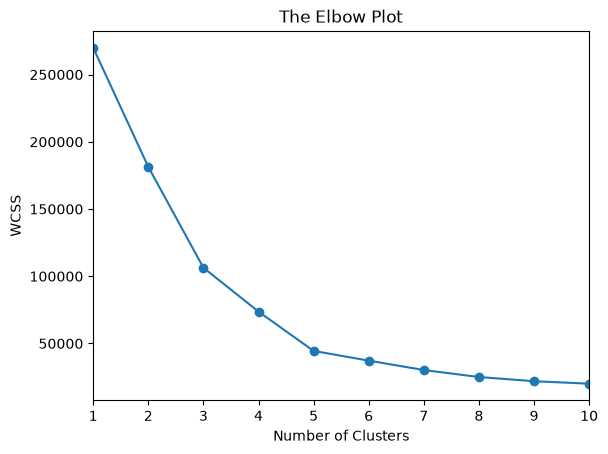

In [13]:
plt.plot(range(1,11), wcss, marker="o")
plt.title("The Elbow Plot")
plt.xlabel("Number of Clusters")
plt.xlim(1, 10)
plt.ylabel("WCSS")
plt.show()

In [14]:
kmeans = KMeans(n_clusters=5, random_state=42)
kmeans.fit(X)

clusters = kmeans.predict(X)
clusters

array([4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2,
       4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 2, 4, 0,
       4, 2, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 3, 1, 0, 1, 3, 1, 3, 1,
       0, 1, 3, 1, 3, 1, 3, 1, 3, 1, 0, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1,
       3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1,
       3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1, 3, 1,
       3, 1], dtype=int32)

In [15]:
kmeans.cluster_centers_

array([[55.2962963 , 49.51851852],
       [86.53846154, 82.12820513],
       [25.72727273, 79.36363636],
       [88.2       , 17.11428571],
       [26.30434783, 20.91304348]])

In [16]:
kmeans.inertia_

44448.4554479337

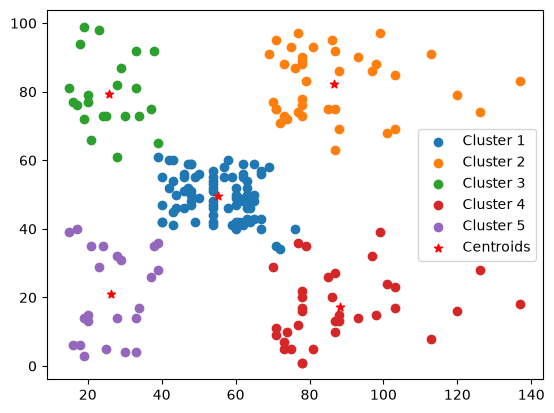

In [17]:
plt.scatter(X.loc[kmeans.labels_ == 0, "Annual Income (k$)"],X.loc[kmeans.labels_ == 0, "Spending Score (1-100)"],label=f"Cluster 1")
plt.scatter(X.loc[kmeans.labels_ == 1, "Annual Income (k$)"],X.loc[kmeans.labels_ == 1, "Spending Score (1-100)"],label=f"Cluster 2")
plt.scatter(X.loc[kmeans.labels_ == 2, "Annual Income (k$)"],X.loc[kmeans.labels_ == 2, "Spending Score (1-100)"],label=f"Cluster 3")
plt.scatter(X.loc[kmeans.labels_ == 3, "Annual Income (k$)"],X.loc[kmeans.labels_ == 3, "Spending Score (1-100)"],label=f"Cluster 4")
plt.scatter(X.loc[kmeans.labels_ == 4, "Annual Income (k$)"],X.loc[kmeans.labels_ == 4, "Spending Score (1-100)"],label=f"Cluster 5")

plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],marker="*", color="red", label="Centroids")

plt.legend()
plt.show()

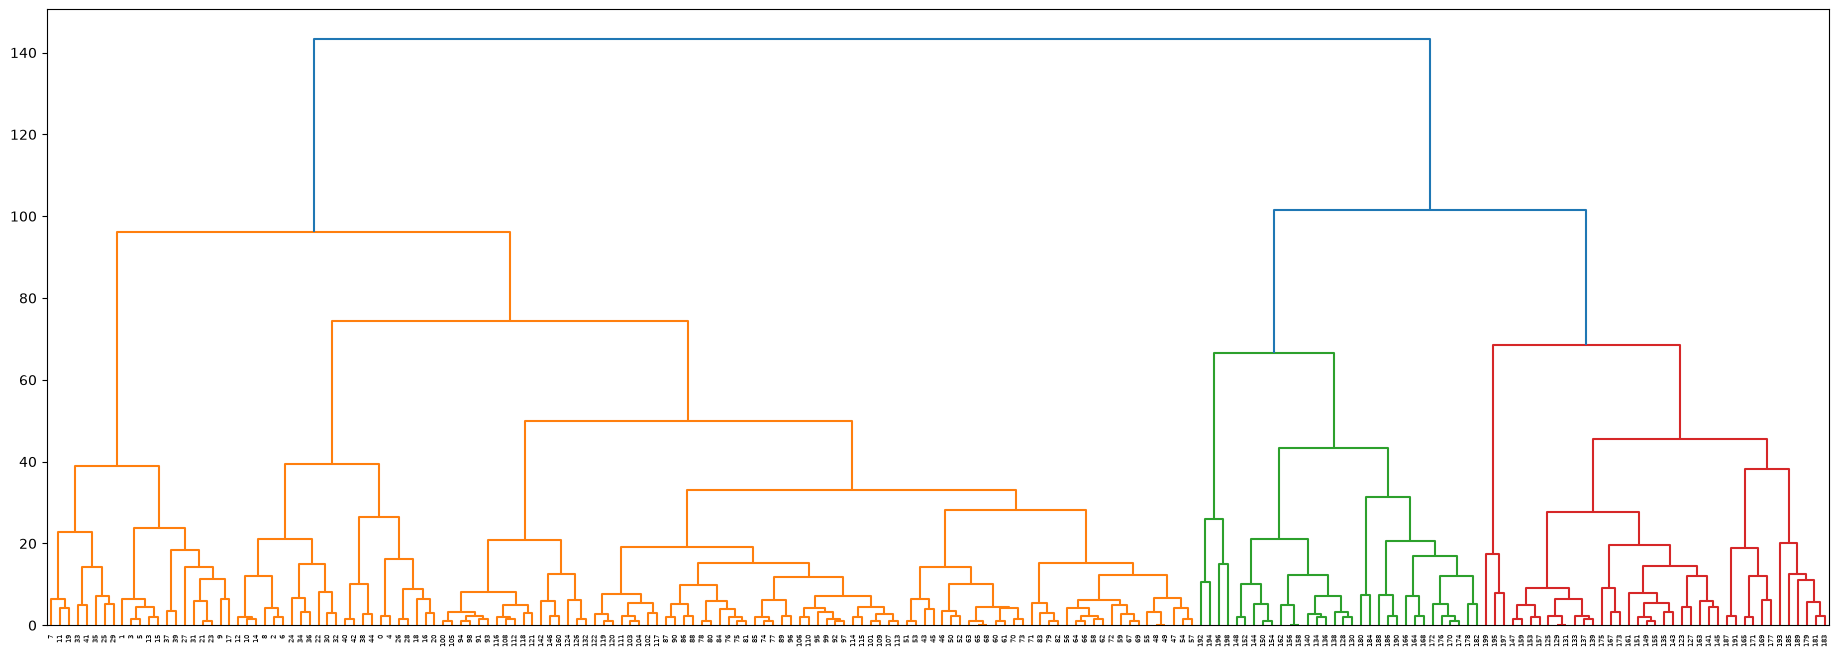

In [18]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(X, 'complete')
fig = plt.figure(figsize=(23, 8))
dn = dendrogram(Z)
plt.show()

User Input

In [19]:
income = float(input("Enter the Annual Income (k$): "))
spending = float(input("Enter the Spending Score (1-100): "))

user_data = pd.DataFrame([[income, spending]], columns=["Annual Income (k$)", "Spending Score (1-100)"])

ans = kmeans.predict(user_data)

print("Your point is in cluster :",ans)

Enter the Annual Income (k$):  50
Enter the Spending Score (1-100):  40


Your point is in cluster : [0]


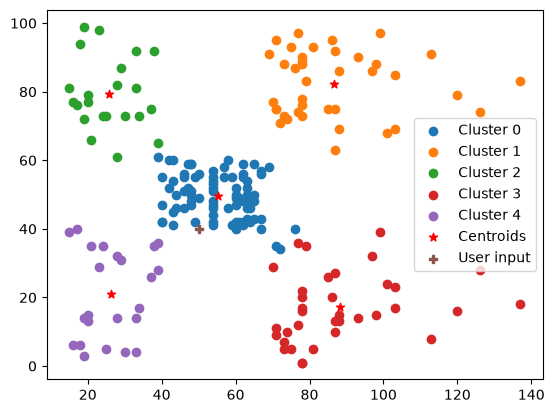

In [20]:
plt.scatter(X.loc[kmeans.labels_ == 0, "Annual Income (k$)"],X.loc[kmeans.labels_ == 0, "Spending Score (1-100)"],label=f"Cluster 0")
plt.scatter(X.loc[kmeans.labels_ == 1, "Annual Income (k$)"],X.loc[kmeans.labels_ == 1, "Spending Score (1-100)"],label=f"Cluster 1")
plt.scatter(X.loc[kmeans.labels_ == 2, "Annual Income (k$)"],X.loc[kmeans.labels_ == 2, "Spending Score (1-100)"],label=f"Cluster 2")
plt.scatter(X.loc[kmeans.labels_ == 3, "Annual Income (k$)"],X.loc[kmeans.labels_ == 3, "Spending Score (1-100)"],label=f"Cluster 3")
plt.scatter(X.loc[kmeans.labels_ == 4, "Annual Income (k$)"],X.loc[kmeans.labels_ == 4, "Spending Score (1-100)"],label=f"Cluster 4")
plt.scatter(kmeans.cluster_centers_[:, 0], kmeans.cluster_centers_[:, 1],marker="*", color="red", label="Centroids")
plt.scatter(user_data["Annual Income (k$)"],user_data["Spending Score (1-100)"],marker='P',label="User input")

plt.legend()
plt.show()